In [ ]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
%pip install -q ultralytics

In [ ]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Ultralytics version: 8.4.190


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg


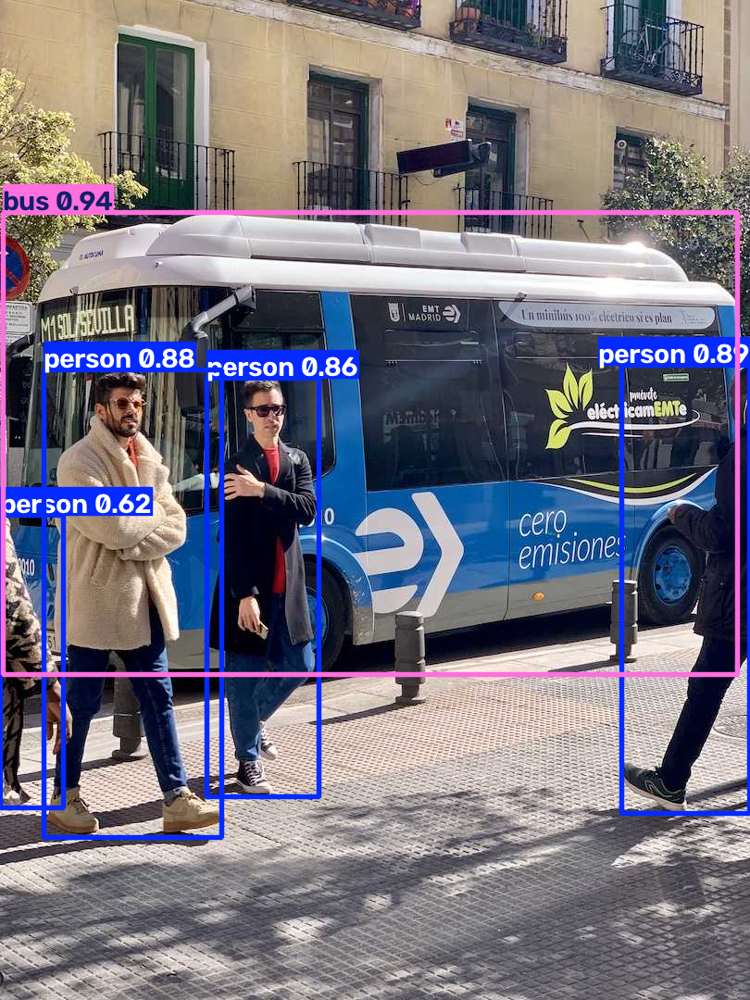

In [ ]:

from ultralytics import YOLO
from IPython.display import display
from PIL import Image

model = YOLO("yolo11n.pt")

results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Visualize detections
display(Image.fromarray(results[0].plot()[..., ::-1]))


In [ ]:

result = results[0]

for box in result.boxes:
    cls_id = int(box.cls[0])
    confidence = float(box.conf[0])
    coordinates = box.xyxy[0].tolist()

    print({
        "class": result.names[cls_id],
        "confidence": round(confidence, 3),
        "bbox": [round(x, 1) for x in coordinates]
    })


{'class': 'bus', 'confidence': 0.94, 'bbox': [3.8, 229.4, 796.2, 728.4]}
{'class': 'person', 'confidence': 0.888, 'bbox': [671.0, 394.8, 809.8, 878.7]}
{'class': 'person', 'confidence': 0.878, 'bbox': [47.4, 399.6, 239.3, 904.2]}
{'class': 'person', 'confidence': 0.856, 'bbox': [223.1, 408.7, 344.5, 860.4]}
{'class': 'person', 'confidence': 0.622, 'bbox': [0.0, 556.1, 68.9, 872.4]}


In [ ]:

from pathlib import Path

ROOT = Path("/content/roadvision")
RAW_DIR = ROOT / "raw"
DATASET_DIR = ROOT / "datasets" / "rdd2022"

RAW_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)


Project root: /content/roadvision


In [ ]:
%pip install -q -U datasets huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.3.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
from datasets import load_dataset

DATASET_ID = "dronefreak/RDD2022"

dataset = load_dataset(
    DATASET_ID,
    split="train",
    streaming=True
)

sample = next(iter(dataset))

print("Available fields:")
print(list(sample.keys()))

for key, value in sample.items():
    if key == "image":
        print("image:", type(value))
    else:
        print(key, ":", str(value)[:400])

README.md:   0%|          | 0.00/11.1k [00:00<?, ?B/s]

Available fields:
['file_name', 'objects']
file_name : China_Drone_000001.jpg
objects : {'bbox': [[14, 70, 184, 29], [95, 114, 25, 158]], 'categories': [1, 0]}


In [ ]:

from datasets import load_dataset, get_dataset_split_names
import random

DATASET_ID = "dronefreak/RDD2022"
SEED = 42

available_splits = get_dataset_split_names(DATASET_ID)
print("Available splits:", available_splits)

val_source = (
    "validation" if "validation" in available_splits
    else "valid" if "valid" in available_splits
    else None
)
assert val_source is not None, "Validation split not found"

split_config = {
    "train": ("train", 300),
    "val": (val_source, 75),
    "test": ("test", 75),
}

def reservoir_sample(stream, n, seed):
    rng = random.Random(seed)
    selected = []

    for i, row in enumerate(stream):
        if i < n:
            selected.append(row)
        else:
            j = rng.randint(0, i)
            if j < n:
                selected[j] = row

    return selected

samples = {}

for split_name, (source_split, count) in split_config.items():
    stream = load_dataset(
        DATASET_ID,
        split=source_split,
        streaming=True
    )

    samples[split_name] = reservoir_sample(
        stream, count, SEED
    )

    print(split_name, len(samples[split_name]))

print("First sample:", samples["train"][0])


Available splits: ['train', 'validation', 'test']
train 300
val 75
test 75
First sample: {'file_name': 'Norway_000891.jpg', 'objects': {'bbox': [[397, 1496, 1428, 60], [325, 1841, 1677, 105], [1030, 1193, 228, 324], [828, 1519, 178, 98], [1085, 1617, 57, 69]], 'categories': [1, 1, 0, 0, 0]}}


In [ ]:

from huggingface_hub import HfApi
from pathlib import PurePosixPath

api = HfApi()

repo_files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

image_lookup = {}

for path in repo_files:
    p = PurePosixPath(path)

    if "/images/" not in f"/{path}":
        continue

    if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    image_lookup.setdefault(p.name, []).append(path)

print("Indexed image filenames:", len(image_lookup))

example = samples["train"][0]["file_name"]
print("Example:", example)
print("Possible paths:", image_lookup.get(example, []))


Indexed image filenames: 38385
Example: Norway_000891.jpg
Possible paths: ['data/images/train/shard_006/Norway_000891.jpg']


In [ ]:

from pathlib import Path
from huggingface_hub import hf_hub_download
from PIL import Image
from collections import Counter
import shutil

ROOT = Path("/content/roadvision")
DATASET_DIR = ROOT / "datasets" / "rdd2022"

CLASS_NAMES = {
    0: "longitudinal_crack",
    1: "transverse_crack",
    2: "alligator_crack",
    3: "pothole"
}

def to_yolo(objects, width, height):
    lines = []

    boxes = objects["bbox"]
    classes = objects["categories"]

    assert len(boxes) == len(classes)

    for box, cls in zip(boxes, classes):
        x, y, w, h = map(float, box)
        cls = int(cls)

        if cls not in CLASS_NAMES:
            continue

        x1 = max(0, min(x, width))
        y1 = max(0, min(y, height))
        x2 = max(0, min(x + w, width))
        y2 = max(0, min(y + h, height))

        if x2 <= x1 or y2 <= y1:
            continue

        xc = (x1 + x2) / (2 * width)
        yc = (y1 + y2) / (2 * height)
        bw = (x2 - x1) / width
        bh = (y2 - y1) / height

        lines.append(
            f"{cls} {xc:.6f} {yc:.6f} "
            f"{bw:.6f} {bh:.6f}"
        )

    return lines


class_counts = Counter()

for split_name, rows in samples.items():
    image_dir = DATASET_DIR / "images" / split_name
    label_dir = DATASET_DIR / "labels" / split_name

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    source_split = split_config[split_name][0]
    folder_name = (
        "valid" if source_split in {"valid", "validation"}
        else source_split
    )

    for i, sample in enumerate(rows):
        filename = sample["file_name"]
        candidate_paths = [
            p for p in image_lookup.get(filename, [])
            if f"/images/{folder_name}/" in f"/{p}"
        ]

        if len(candidate_paths) != 1:
            raise ValueError(
                f"Ambiguous or missing image: {filename} "
                f"{candidate_paths}"
            )

        source_path = hf_hub_download(
            repo_id=DATASET_ID,
            repo_type="dataset",
            filename=candidate_paths[0]
        )

        new_stem = f"{split_name}_{i:05d}"
        suffix = Path(filename).suffix.lower()

        dst_image = image_dir / (new_stem + suffix)
        dst_label = label_dir / (new_stem + ".txt")

        shutil.copy2(source_path, dst_image)

        with Image.open(dst_image) as image:
            width, height = image.size

        lines = to_yolo(
            sample["objects"], width, height
        )

        dst_label.write_text(
            "\n".join(lines),
            encoding="utf-8"
        )

        for line in lines:
            class_counts[int(line.split()[0])] += 1

    print(f"Completed {split_name}: {len(rows)} images")

print("Class counts:", dict(class_counts))


data/images/train/shard_006/Norway_00089(…): reconstructing file:   0%|          |  0.00B / 1.54MB            

data/images/train/shard_006/Norway_00089(…): downloading bytes:           |  0.00B            

data/images/train/shard_007/Norway_00762(…): reconstructing file:   0%|          |  0.00B /  756kB            

data/images/train/shard_007/Norway_00762(…): downloading bytes:           |  0.00B            

data/images/train/shard_001/India_001652(…): reconstructing file:   0%|          |  0.00B / 81.9kB            

data/images/train/shard_001/India_001652(…): downloading bytes:           |  0.00B            

... (893 outputs left out)

data/images/test/shard_000/India_000965.(…): downloading bytes:           |  0.00B            

data/images/test/shard_000/China_MotorBi(…): reconstructing file:   0%|          |  0.00B / 97.5kB            

data/images/test/shard_000/China_MotorBi(…): downloading bytes:           |  0.00B            

Completed test: 75 images
Class counts: {1: 160, 0: 312, 2: 113, 3: 121}


In [ ]:

import yaml

config = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": CLASS_NAMES
}

yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(yaml_path.read_text())


path: /content/roadvision/datasets/rdd2022
train: images/train
val: images/val
test: images/test
names:
  0: longitudinal_crack
  1: transverse_crack
  2: alligator_crack
  3: pothole



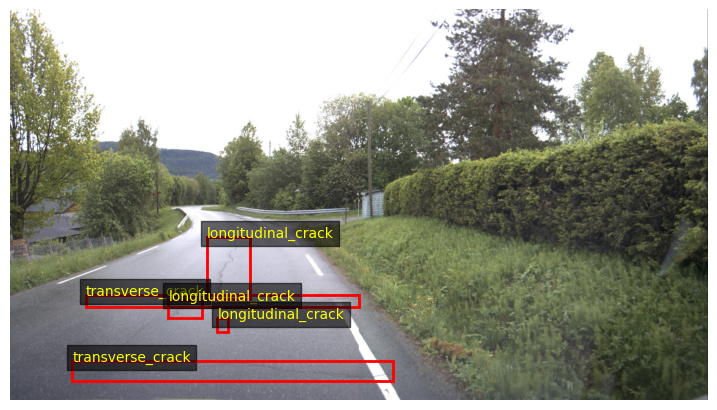

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

image_path = sorted(
    (DATASET_DIR / "images/train").glob("*")
)[0]

label_path = (
    DATASET_DIR / "labels/train" /
    (image_path.stem + ".txt")
)

image = Image.open(image_path).convert("RGB")
W, H = image.size

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(image)

for line in label_path.read_text().splitlines():
    cls, xc, yc, bw, bh = map(float, line.split())

    x = (xc - bw / 2) * W
    y = (yc - bh / 2) * H

    rect = patches.Rectangle(
        (x, y),
        bw * W,
        bh * H,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.text(
        x, y,
        CLASS_NAMES[int(cls)],
        color="yellow",
        bbox=dict(facecolor="black", alpha=0.6)
    )

ax.axis("off")
plt.show()


Dataset statistics:
train {'images': 300, 'boxes': 469, 'empty_images': 103}
val {'images': 75, 'boxes': 139, 'empty_images': 20}
test {'images': 75, 'boxes': 98, 'empty_images': 31}

Class distribution:
longitudinal_crack 312
transverse_crack 160
alligator_crack 113
pothole 121


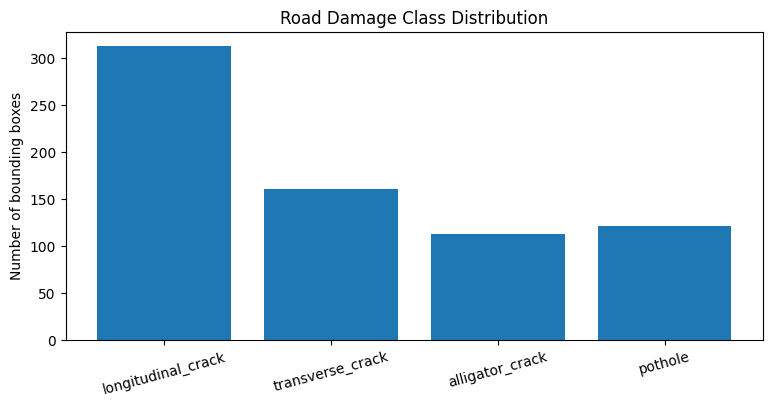

In [ ]:

from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

split_stats = {}
class_counts = Counter()

for split in ["train", "val", "test"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    n_boxes = 0
    empty_images = 0

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"
        assert label_path.exists(), f"Missing label: {label_path}"

        lines = label_path.read_text().splitlines()

        if not lines:
            empty_images += 1

        for line in lines:
            parts = line.split()
            assert len(parts) == 5

            cls = int(parts[0])
            coords = [float(x) for x in parts[1:]]

            assert cls in range(4)
            assert all(0 <= v <= 1 for v in coords)
            assert coords[2] > 0 and coords[3] > 0

            class_counts[cls] += 1
            n_boxes += 1

    split_stats[split] = {
        "images": len(images),
        "boxes": n_boxes,
        "empty_images": empty_images
    }

print("Dataset statistics:")
for split, stats in split_stats.items():
    print(split, stats)

print("\nClass distribution:")
for cls_id, name in CLASS_NAMES.items():
    print(name, class_counts[cls_id])

plt.figure(figsize=(9, 4))
plt.bar(
    [CLASS_NAMES[i] for i in range(4)],
    [class_counts[i] for i in range(4)]
)
plt.title("Road Damage Class Distribution")
plt.ylabel("Number of bounding boxes")
plt.xticks(rotation=15)
plt.show()


In [ ]:

from ultralytics import YOLO
import torch
from pathlib import Path

device = 0 if torch.cuda.is_available() else "cpu"

print("Training device:", device)

model = YOLO("yolo11n.pt")

train_results = model.train(
    data=str(yaml_path),
    epochs=20,
    imgsz=640,
    batch=8,
    device=device,
    patience=7,
    seed=42,
    project=str(ROOT / "runs"),
    name="roadvision_yolo11n_v1",
    exist_ok=True,
    plots=True
)

print("Training completed!")


Training device: 0
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roadvision/datasets/rdd2022/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=roadvision_yolo11n_v1, nb

In [ ]:

from ultralytics import YOLO

best_path = (
    ROOT / "runs" /
    "roadvision_yolo11n_v1" /
    "weights" / "best.pt"
)

assert best_path.exists(), "Model checkpoint not found"

best_model = YOLO(str(best_path))

metrics = best_model.val(
    data=str(yaml_path),
    split="val",
    device=device,
    plots=True
)

print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP@0.5:", round(metrics.box.map50, 4))
print("mAP@0.5:0.95:", round(metrics.box.map, 4))


Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1959.3±606.3 MB/s, size: 64.6 KB)
val: Scanning /content/roadvision/datasets/rdd2022/labels/val.cache... 75 images, 20 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 26.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.6it/s 3.1s
                   all         75        139      0.221      0.186      0.126     0.0562
    longitudinal_crack         35         65      0.423      0.215      0.215      0.094
      transverse_crack         20         38     0.0435     0.0263     0.0223    0.00799
       alligator_crack         17         23      0.169      0.348      0.141     0.0679
               pothole         11         13       0.25      0.154      0.124      0.055
Speed: 6.6ms preprocess, 8.8ms 

Saving 20211019_114101.jpg to 20211019_114101.jpg

image 1/1 /content/20211019_114101.jpg: 416x640 (no detections), 8.2ms
Speed: 1.9ms preprocess, 8.2ms inference, 0.6ms postprocess per image at shape (1, 3, 416, 640)


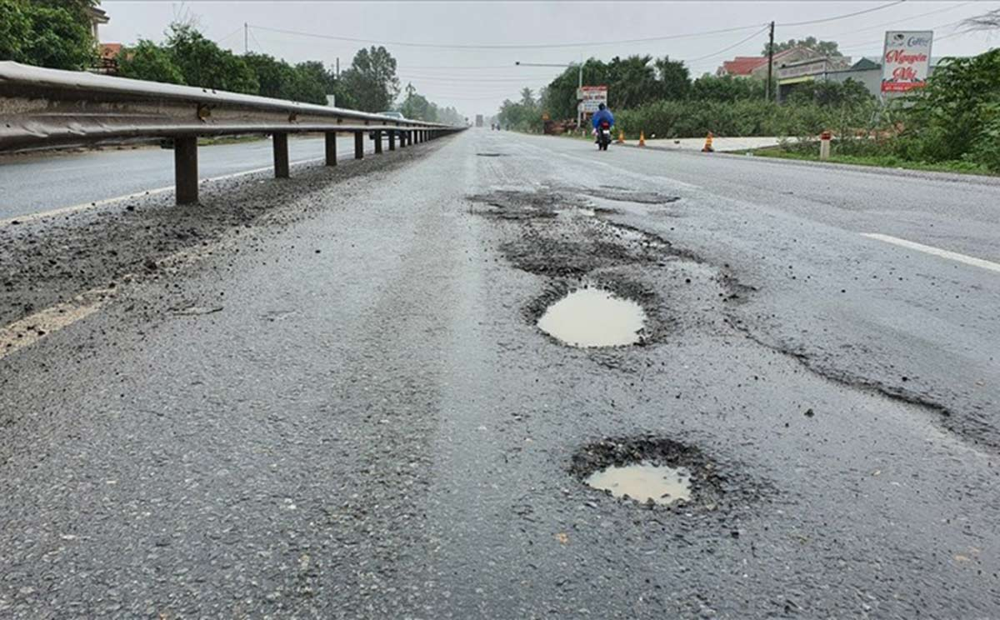

In [ ]:

from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

for filename in uploaded:
    predictions = best_model.predict(
        source=filename,
        conf=0.25,
        imgsz=640
    )

    display(
        Image.fromarray(
            predictions[0].plot()[..., ::-1]
        )
    )



Confidence threshold: 0.25
Detections: 0


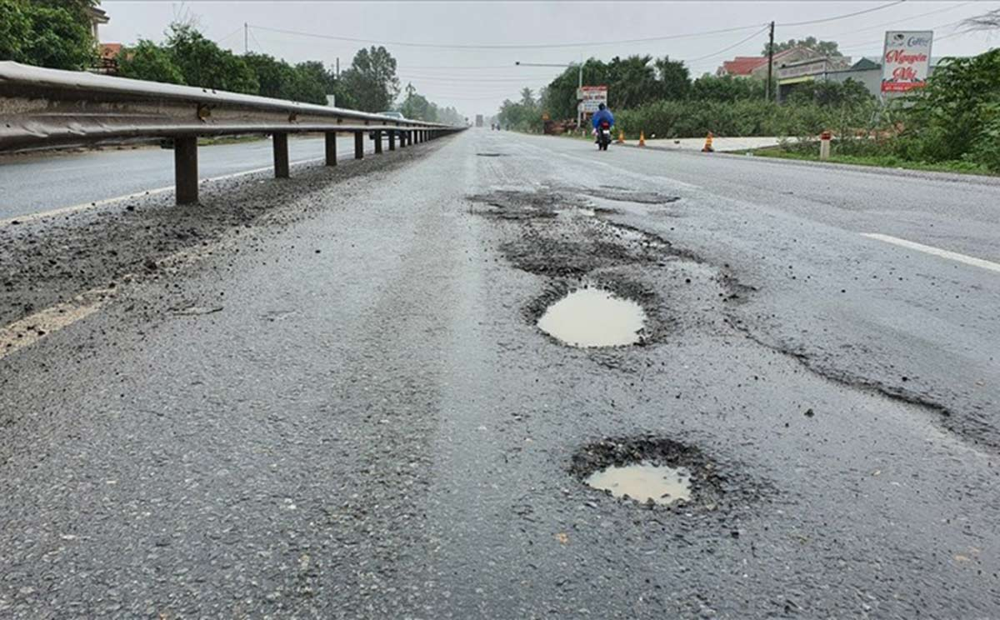


Confidence threshold: 0.1
Detections: 1
alligator_crack 0.181


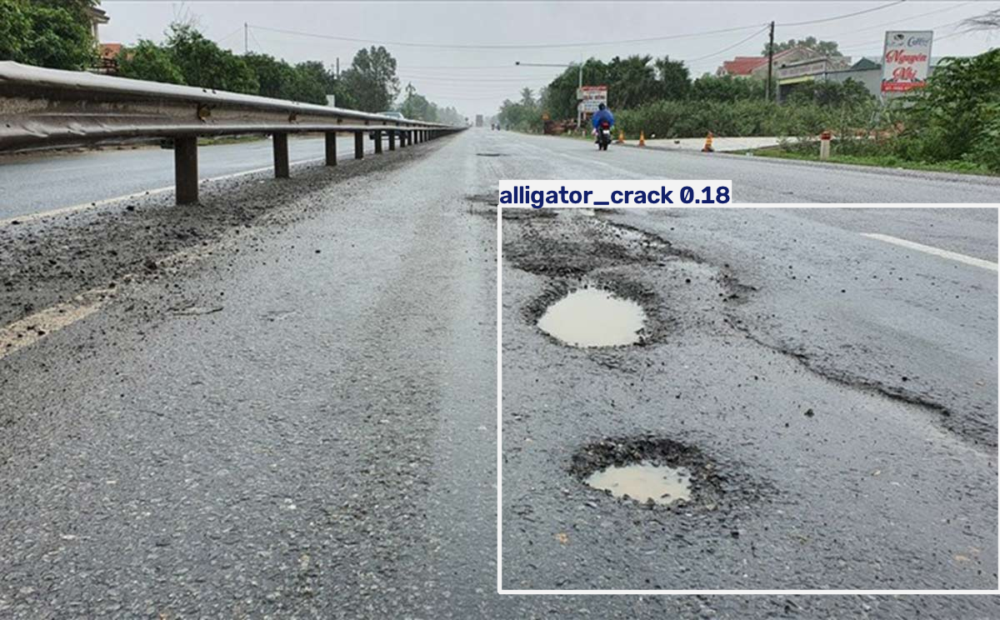


Confidence threshold: 0.05
Detections: 2
alligator_crack 0.181
alligator_crack 0.066


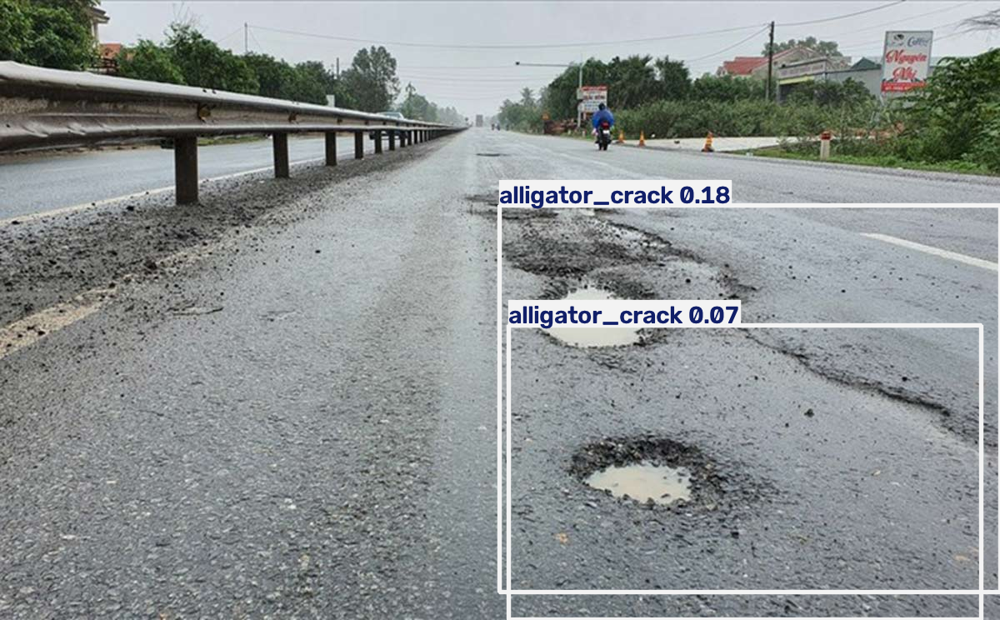

In [ ]:

from PIL import Image
from IPython.display import display

image_path = "/content/20211019_114101.jpg"

for threshold in [0.25, 0.10, 0.05]:
    results = best_model.predict(
        source=image_path,
        conf=threshold,
        imgsz=640,
        verbose=False
    )

    result = results[0]

    print(f"\nConfidence threshold: {threshold}")
    print(f"Detections: {len(result.boxes)}")

    for box in result.boxes:
        cls_id = int(box.cls[0])
        print(
            result.names[cls_id],
            round(float(box.conf[0]), 3)
        )

    display(Image.fromarray(
        result.plot()[..., ::-1]
    ))


In [ ]:
metrics = best_model.val(
    data=str(yaml_path),
    split="val",
    device=device
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2403.3±1469.5 MB/s, size: 266.7 KB)
val: Scanning /content/roadvision/datasets/rdd2022/labels/val.cache... 75 images, 20 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 19.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7it/s 2.9s
                   all         75        139      0.221      0.186      0.126     0.0562
    longitudinal_crack         35         65      0.423      0.215      0.215      0.094
      transverse_crack         20         38     0.0435     0.0263     0.0223    0.00799
       alligator_crack         17         23      0.169      0.348      0.141     0.0679
               pothole         11         13       0.25      0.154      0.124      0.055
Speed: 5.9ms preprocess, 5.3m

In [ ]:

from google.colab import drive
from pathlib import Path
import shutil
import json
import torch
import ultralytics

drive.mount("/content/drive")

# Model storage
DEST = Path("/content/drive/MyDrive/RoadVision/models/v1")
DEST.mkdir(parents=True, exist_ok=True)

# Verify checkpoint exists
assert best_path.exists(), f"Missing checkpoint: {best_path}"

# Save model
saved_model = DEST / "best.pt"
shutil.copy2(best_path, saved_model)

# Save training dataset configuration
shutil.copy2(yaml_path, DEST / "data.yaml")

# Save evaluation metadata
metadata = {
    "model_name": "YOLO11n",
    "model_version": "v1",
    "dataset": "RDD2022 subset",
    "train_images": 300,
    "val_images": 75,
    "test_images": 75,
    "epochs_configured": 20,
    "image_size": 640,
    "batch_size": 8,
    "seed": 42,
    "metrics": {
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "map50": float(metrics.box.map50),
        "map50_95": float(metrics.box.map)
    },
    "environment": {
        "torch": torch.__version__,
        "ultralytics": ultralytics.__version__
    }
}

with open(DEST / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", saved_model)
print("Saved files:")
for file in DEST.iterdir():
    print(file.name)


Mounted at /content/drive
Saved model: /content/drive/MyDrive/RoadVision/models/v1/best.pt
Saved files:
best.pt
data.yaml
metadata.json


In [ ]:
import shutil

archive_path = shutil.make_archive(
    "/content/roadvision_rdd2022_v1",
    "zip",
    root_dir=str(DATASET_DIR)
)

drive_dataset_dir = Path(
    "/content/drive/MyDrive/RoadVision/datasets"
)
drive_dataset_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    archive_path,
    drive_dataset_dir / "rdd2022_subset_v1.zip"
)

print("Dataset backup completed!")

Dataset backup completed!


In [ ]:
%pip install -q mlflow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.


In [ ]:
import mlflow

print("MLflow version:", mlflow.__version__)

MLflow version: 3.17.2


In [ ]:

from google.colab import drive
from pathlib import Path
import json

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/RoadVision")
V1_DIR = DRIVE_ROOT / "models" / "v1"

model_path = V1_DIR / "best.pt"
config_path = V1_DIR / "data.yaml"
metadata_path = V1_DIR / "metadata.json"

for path in [model_path, config_path, metadata_path]:
    print(path.name, "Exists:", path.exists())

assert all(
    p.exists() for p in [model_path, config_path, metadata_path]
), "Missing baseline files on Google Drive"

with open(metadata_path, "r") as f:
    baseline_metadata = json.load(f)

print(json.dumps(baseline_metadata, indent=2))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
best.pt Exists: True
data.yaml Exists: True
metadata.json Exists: True
{
  "model_name": "YOLO11n",
  "model_version": "v1",
  "dataset": "RDD2022 subset",
  "train_images": 300,
  "val_images": 75,
  "test_images": 75,
  "epochs_configured": 20,
  "image_size": 640,
  "batch_size": 8,
  "seed": 42,
  "metrics": {
    "precision": 0.2214061858247467,
    "recall": 0.1858431614152438,
    "map50": 0.12550362730956546,
    "map50_95": 0.05621294291432901
  },
  "environment": {
    "torch": "2.11.0+cu130",
    "ultralytics": "8.4.190"
  }
}


In [ ]:

import mlflow
from pathlib import Path

TRACKING_ROOT = Path("/content/roadvision_mlflow")
TRACKING_ROOT.mkdir(parents=True, exist_ok=True)

DB_PATH = TRACKING_ROOT / "mlflow.db"
ARTIFACT_ROOT = TRACKING_ROOT / "artifacts"
ARTIFACT_ROOT.mkdir(exist_ok=True)

# Restore previously backed-up tracking files if available.
# This becomes useful after a Colab runtime reset.
import shutil

BACKUP_ROOT = DRIVE_ROOT / "mlflow_backup"

if not DB_PATH.exists() and (BACKUP_ROOT / "mlflow.db").exists():
    shutil.copy2(BACKUP_ROOT / "mlflow.db", DB_PATH)

    if (BACKUP_ROOT / "artifacts").exists():
        shutil.copytree(
            BACKUP_ROOT / "artifacts",
            ARTIFACT_ROOT,
            dirs_exist_ok=True
        )

TRACKING_URI = f"sqlite:///{DB_PATH}"

mlflow.set_tracking_uri(TRACKING_URI)

experiment_name = "RoadVision-Detection"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        experiment_name,
        artifact_location=ARTIFACT_ROOT.as_uri()
    )
else:
    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_name)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment ID:", experiment_id)


2026/10/27 16:40:37 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 16:40:37 INFO mlflow.store.db.utils: Updating database tables


Tracking URI: sqlite:////content/roadvision_mlflow/mlflow.db
Experiment ID: 1


In [ ]:

import mlflow
import hashlib
import json

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

m = baseline_metadata["metrics"]

params = {
    "model": "yolo11n",
    "dataset": "RDD2022-subset-v1",
    "train_images": baseline_metadata["train_images"],
    "val_images": baseline_metadata["val_images"],
    "test_images": baseline_metadata["test_images"],
    "epochs_configured": baseline_metadata["epochs_configured"],
    "imgsz": baseline_metadata["image_size"],
    "batch": baseline_metadata["batch_size"],
    "seed": baseline_metadata["seed"]
}

run_metrics = {
    "precision": float(m["precision"]),
    "recall": float(m["recall"]),
    "map50": float(m["map50"]),
    "map50_95": float(m["map50_95"])
}

with mlflow.start_run(run_name="baseline-v1-import") as run:
    mlflow.log_params(params)
    mlflow.log_metrics(run_metrics)

    mlflow.set_tags({
        "project": "RoadVision",
        "phase": "baseline",
        "model_version": "v1",
        "source": "imported_from_previous_colab_training",
        "training_status": "completed"
    })

    mlflow.log_artifact(
        str(model_path),
        artifact_path="model"
    )

    mlflow.log_artifact(
        str(config_path),
        artifact_path="config"
    )

    mlflow.log_artifact(
        str(metadata_path),
        artifact_path="metadata"
    )

    mlflow.log_dict(
        {
            "checkpoint_sha256": sha256_file(model_path),
            "notes": (
                "Imported historical baseline. "
                "Training was not executed in this MLflow run."
            )
        },
        "provenance.json"
    )

    print("MLflow Run ID:", run.info.run_id)

print("Baseline v1 registered in MLflow Tracking!")


MLflow Run ID: 8874b0e680144da89e39381f5d920e3a
Baseline v1 registered in MLflow Tracking!


In [ ]:

from mlflow.tracking import MlflowClient

client = MlflowClient()

experiment = client.get_experiment_by_name(
    "RoadVision-Detection"
)

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=20
)

print("Total runs:", len(runs))

for run in runs:
    print("\nRun ID:", run.info.run_id)
    print("Run name:", run.data.tags.get("mlflow.runName"))
    print("mAP50:", run.data.metrics.get("map50"))
    print("mAP50-95:", run.data.metrics.get("map50_95"))
    print("Model:", run.data.params.get("model"))


Total runs: 1

Run ID: 8874b0e680144da89e39381f5d920e3a
Run name: baseline-v1-import
mAP50: 0.12550362730956546
mAP50-95: 0.05621294291432901
Model: yolo11n


In [ ]:

import sqlite3
import shutil

BACKUP_ROOT = DRIVE_ROOT / "mlflow_backup"
BACKUP_ROOT.mkdir(parents=True, exist_ok=True)

# Consistent SQLite backup
source_connection = sqlite3.connect(str(DB_PATH))
target_connection = sqlite3.connect(
    str(BACKUP_ROOT / "mlflow.db")
)

with target_connection:
    source_connection.backup(target_connection)

target_connection.close()
source_connection.close()

# Save experiment artifacts
if (BACKUP_ROOT / "artifacts").exists():
    shutil.rmtree(BACKUP_ROOT / "artifacts")

shutil.copytree(
    ARTIFACT_ROOT,
    BACKUP_ROOT / "artifacts"
)

print("MLflow backup completed!")
print("Backup location:", BACKUP_ROOT)


MLflow backup completed!
Backup location: /content/drive/MyDrive/RoadVision/mlflow_backup
